In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle

sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

import fracprolif as fp
from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction
from call_cell_events import call_events #
from retrieve_cellState_dw_2 import retrieve_cellState #

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

SAVE_CELL_DATA = False

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt('model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv('test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [6]:
with open('fit_data/pso/frac_prolif_parameters_pso.pkl', 'rb') as f:
    frac_prolif_parameters_pso = pickle.load(f)
new_param_pso_sort = frac_prolif_parameters_pso.sort_values([('cost', 'total cost likelihood')])
new_params = new_param_pso_sort['model parameters']
# Importing the parameters:
ii = 0
for key in new_params.keys():
    try:
        if model.parameters[key].value != new_params[key].iloc[ii]:
            model.parameters[key].value = new_params[key].iloc[ii]
    except:
        print(key)
model.parameters['omega'].value = 200

In [19]:
new_param_pso_sort

pso           fractional proliferation model                  \
   chain iteration                 a 0.6 kPa DMSO mu 0.6 kPa DMSO   
0     23         7                       0.004162       20.516537   
0      8        15                       0.000000       21.752535   
0      8        33                       0.000257       21.803864   
0     31        47                       0.000000       17.538867   
0     12        34                       0.000916       22.359029   
..   ...       ...                            ...             ...   
0      2        35                       0.018949       19.637748   
0      3        46                       0.013697       18.009089   
0      3        33                       0.014886       20.735732   
0      3        32                       0.010060       18.948334   
0     33        62                            NaN             NaN   

                                                                         \
   sigma 0.6 kPa DMSO lambda 0.6 kPa DMSO d 0.6 kPa DMSO q 0.6 kPa DMSO   
0            3.265346            0.176240       0.027022   3.085353e-04   
0            7.124669            0.132901       0.024714   3.190317e-05   
0            5.946628            0.139915       0.024802   0.000000e+00   
0            7.284711            0.029068       0.015480   0.000000e+00   
0            6.198858            0.189520       0.025853   5.644035e-15   
..                ...                 ...            ...            ...   
0            1.441140            0.207753       0.028742   3.276820e-18   
0            1.899194            0.091724       0.025114   2.511401e-43   
0            1.893846            0.096399       0.023110   2.851995e-04   
0            1.496340            0.069578       0.022070   2.206982e-43   
0                 NaN                 NaN            NaN            NaN   

                                             ...        cost  \
   a 0.6 kPa erlotinib mu 0.6 kPa erlotinib  ... cost custom   
0             0.003211            24.335820  ...    0.377587   
0             0.000000            65.699333  ...    0.556308   
0             0.000781            75.718569  ...    0.445416   
0             0.000000             5.117553  ...    0.254143   
0             0.003114            38.184665  ...    0.404061   
..                 ...                  ...  ...         ...   
0             0.023396            24.808311  ...    0.398512   
0             0.020316                  NaN  ...    0.398064   
0             0.013959                  NaN  ...    0.411087   
0             0.013613                  NaN  ...    0.409827   
0                  NaN                  NaN  ...         NaN   

                                                                           \
   cost 0.6 kPa DMSO cost 0.6 kPa erlotinib cost 0.6 kPa cost 55 kPa DMSO   
0           0.187125               0.223594     0.410719         0.203756   
0           0.253758               0.133060     0.386818         0.183498   
0           0.303802               0.286756     0.590558         0.107822   
0           0.332364               0.419150     0.751515         0.278662   
0           0.293719               0.515068     0.808787         0.108709   
..               ...                    ...          ...              ...   
0           0.231589                    NaN          NaN         0.320223   
0           0.242185                    NaN          NaN         0.153725   
0           0.281456                    NaN          NaN         0.169286   
0           0.288235                    NaN          NaN         0.222869   
0                NaN                    NaN          NaN              NaN   

                                           umap             \
   cost 55 kPa erlotinib cost 55 kPa      dim 1      dim 2   
0               0.468790    0.672546  -0.783923   6.317681   
0               0.467496    0.650995  -0.080293   4.823901   
0               0.505844    0.613666  -0.348885 

In [26]:
pso_sort_pops = frac_prolif_parameters_pso.sort_values(by=[('cost', 'cost population dynamics 0.6 kPa DMSO'), ('cost', 'cost population dynamics 4 kPa erlotinib'), ('cost', 'cost population dynamics 55 kPa erlotinib')])
pso_sort_pops


pso           fractional proliferation model                  \
   chain iteration                 a 0.6 kPa DMSO mu 0.6 kPa DMSO   
0     31        47                       0.000000       17.538867   
0      8        56                       0.000000       18.633506   
0     31        56                       0.000000       18.666911   
0     20        26                       0.014739       21.456106   
0      9        58                       0.013051       19.309775   
..   ...       ...                            ...             ...   
0      1        20                       0.042508       18.791431   
0      1        26                       0.036690       17.900717   
0      1        24                       0.036864       20.347795   
0      1        23                       0.036375       14.634973   
0     33        62                            NaN             NaN   

                                                                         \
   sigma 0.6 kPa DMSO lambda 0.6 kPa DMSO d 0.6 kPa DMSO q 0.6 kPa DMSO   
0            7.284711            0.029068       0.015480   0.000000e+00   
0            0.010000            0.020691       0.012247   1.224740e-43   
0            1.276679            0.026966       0.014321   1.432145e-43   
0            2.492476            0.964140       0.030971   3.097063e-43   
0            1.700738            0.141399       0.026924   2.692400e-43   
..                ...                 ...            ...            ...   
0            2.639047            1.497016       0.035865   2.034891e-16   
0            3.134505            1.507444       0.037726   2.288675e-17   
0            3.745226            1.214628       0.033119   2.132602e-17   
0            3.074952            0.222187       0.037226   1.768037e-17   
0                 NaN                 NaN            NaN            NaN   

                                             ...        cost  \
   a 0.6 kPa erlotinib mu 0.6 kPa erlotinib  ... cost custom   
0             0.000000             5.117553  ...    0.254143   
0             0.000000                  NaN  ...    0.348674   
0             0.000000            81.238072  ...    0.296838   
0             0.020590            14.217571  ...    0.251549   
0             0.018534            42.504666  ...    0.369942   
..                 ...                  ...  ...         ...   
0             0.039851            13.620872  ...         NaN   
0             0.033643            16.863087  ...         NaN   
0             0.044720            15.477231  ...         NaN   
0             0.034250            17.900420  ...         NaN   
0                  NaN                  NaN  ...         NaN   

                                                                           \
   cost 0.6 kPa DMSO cost 0.6 kPa erlotinib cost 0.6 kPa cost 55 kPa DMSO   
0           0.332364               0.419150     0.751515         0.278662   
0           0.392495                    NaN          NaN         0.199833   
0           0.453257               0.752845     1.206102         0.156390   
0           0.150830               0.734423     0.885254         0.288486   
0           0.244042               0.620614     0.864656         0.165057   
..               ...                    ...          ...              ...   
0                NaN                    NaN          NaN         1.563704   
0                NaN                    NaN          NaN         1.338737   
0                NaN                    NaN          NaN         1.514754   
0                NaN                    NaN          NaN         1.507768   
0                NaN                    NaN          NaN              NaN   

                                           umap             \
   cost 55 kPa erlotinib cost 55 kPa      dim 1      dim 2   
0               0.289368    0.568030  -8.631745   2.121151   
0               0.508490    0.708323  -0.008570  -9.250783   
0               0.432529    0.588919  -8.801115 

In [27]:
frac_prolif_parameters_pso[('cost', 'custom cost populations')] = frac_prolif_parameters_pso[('cost', 'cost population dynamics 0.6 kPa DMSO')] + frac_prolif_parameters_pso[('cost', 'cost population dynamics 4 kPa erlotinib')] + frac_prolif_parameters_pso[('cost', 'cost population dynamics 55 kPa erlotinib')]
pso_sort_pops = frac_prolif_parameters_pso.sort_values(by=[('cost', 'custom cost populations')])

In [29]:

new_params = pso_sort_pops['model parameters']
# Importing the parameters:
ii = 0
for key in new_params.keys():
    try:
        if model.parameters[key].value != new_params[key].iloc[ii]:
            model.parameters[key].value = new_params[key].iloc[ii]
    except:
        print(key)
model.parameters['omega'].value = 200

In [30]:
def change_params(param_num):
    for key in new_params.keys():
        try:
            if model.parameters[key].value != new_params[key].iloc[param_num]:
                model.parameters[key].value = new_params[key].iloc[param_num]
        except:
            print(key)

In [5]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv('model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

BAXm_0
BCL2_0


In [7]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv('model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


In [11]:
init = 5
run_time = 120
observed_cells_time = 120
condition = "55 kPa erlotinib"
size = (7,3)

In [13]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO', '4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']

0.6 kPa erlotinib
BAXm_0
BCL2_0
0.6 kPa DMSO
BAXm_0
BCL2_0
4 kPa erlotinib
BAXm_0
BCL2_0
4 kPa DMSO
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa DMSO
BAXm_0
BCL2_0
0.6 kPa erlotinib
BAXm_0
BCL2_0
0.6 kPa DMSO
BAXm_0
BCL2_0
4 kPa erlotinib
BAXm_0
BCL2_0
4 kPa DMSO
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa DMSO
BAXm_0
BCL2_0
0.6 kPa erlotinib
BAXm_0
BCL2_0
0.6 kPa DMSO
BAXm_0
BCL2_0
4 kPa erlotinib
BAXm_0
BCL2_0
4 kPa DMSO
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa DMSO
BAXm_0
BCL2_0
0.6 kPa erlotinib
BAXm_0
BCL2_0
0.6 kPa DMSO
BAXm_0
BCL2_0
4 kPa erlotinib
BAXm_0
BCL2_0
4 kPa DMSO
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa DMSO
BAXm_0
BCL2_0
0.6 kPa erlotinib
BAXm_0
BCL2_0
0.6 kPa DMSO
BAXm_0
BCL2_0
4 kPa erlotinib
BAXm_0
BCL2_0
4 kPa DMSO
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa DMSO
BAXm_0
BCL2_0
0.6 kPa erlotinib
BAXm_0
BCL2_0
0.6 kPa DMSO
BAXm_0
BCL2_0
4 kPa erlotinib
BAXm_0
BCL2_0
4 kPa DMSO
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0


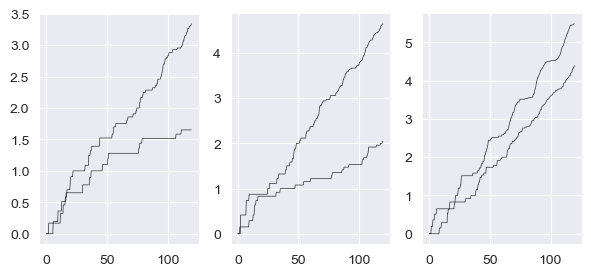

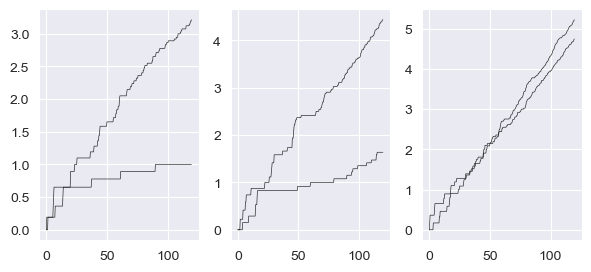

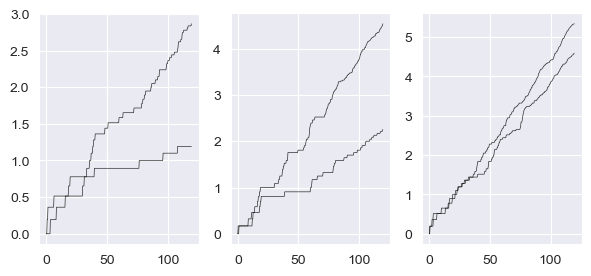

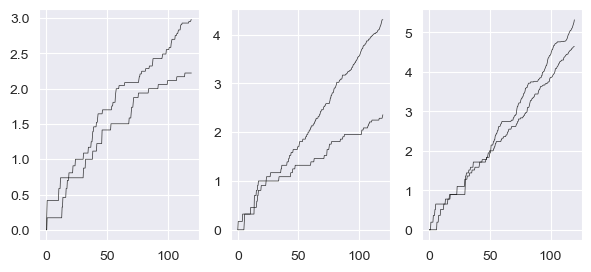

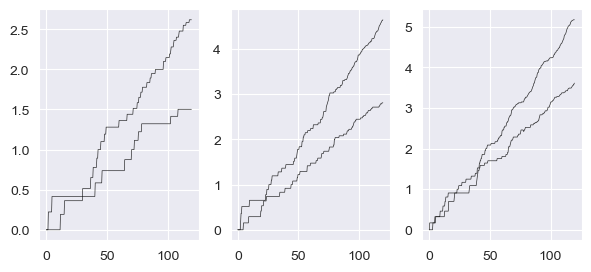

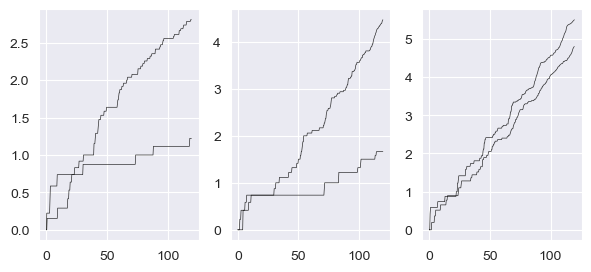

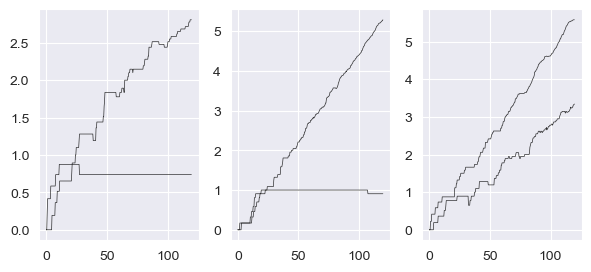

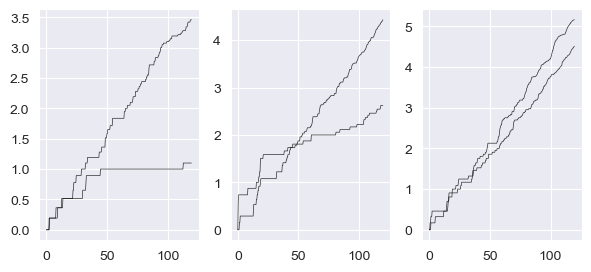

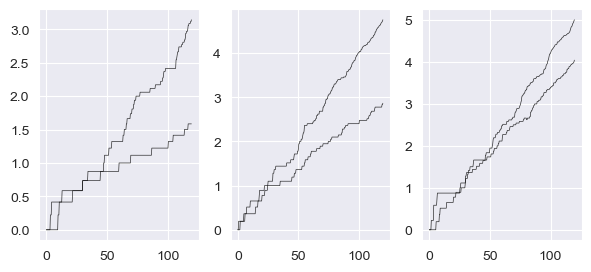

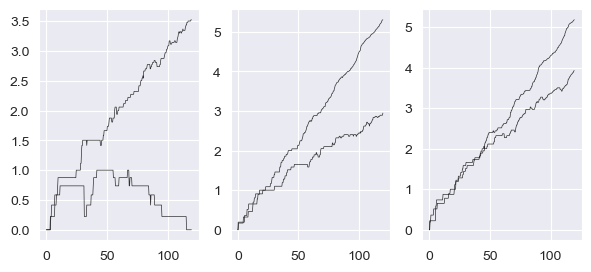

In [31]:
for num in range(10):
    change_params(num)
    
    fig, axes = plt.subplots(1, 3, figsize=size)
    
    for condition in conditions:
        init = 5
            
        (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
        
        if "0.6" in condition:
            n = 0
        elif "4" in condition:
            n = 1
        else:
            n = 2
            
        add_plot(cell_count, run_time, fig, axes[n], title=condition)
        
        
    fig_path = Path(SAVE_DIR, f'PSO_pops_custom_{num}.svg')
    plt.savefig(fig_path, bbox_inches='tight')

0.6 kPa erlotinib
BAXm_0
BCL2_0
0.6 kPa DMSO
BAXm_0
BCL2_0
4 kPa erlotinib
BAXm_0
BCL2_0
4 kPa DMSO
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa DMSO
BAXm_0
BCL2_0


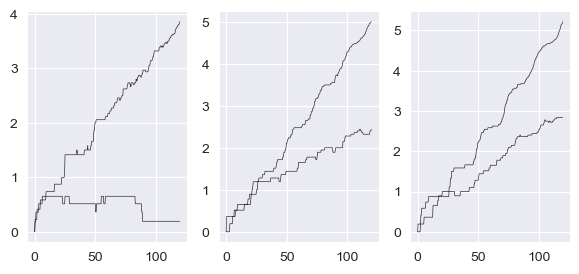

In [14]:
num = 0
change_params(num)

fig, axes = plt.subplots(1, 3, figsize=size)

for condition in conditions:
    init = 5
        
    (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
    
    if "0.6" in condition:
        n = 0
    elif "4" in condition:
        n = 1
    else:
        n = 2
        
    add_plot(cell_count, run_time, fig, axes[n], title=condition)
    
    
fig_path = Path(SAVE_DIR, f'PSO_pops_{num}.svg')
plt.savefig(fig_path, bbox_inches='tight')